# CU-BEMS Starter EDA - Floor 4 (Jul 2018 - Dec 2019)

**Purpose of this notebook:** 
Conducting comprehensive exploratory data analysis (EDA) on Floor 4 of the Chulalongkorn University building to assess data quality, identify anomalies, and profile energy consumption:

1. **Describe the Floor 4 Dataset**: Structure, channels, zones, and sampling fidelity.
2. **Missing Data Diagnostics**: Gap identification, missingness share, and blackout detection.
3. **Sensor & Meter Glitch Detection**: Impossible values, transients, and asymmetric loads.
4. **Energy Consumption Breakdown**: Sub-metered end-use (AC, Lighting, Plug loads) and zone dynamics.
5. **Typical Operating Profiles**: Diurnal curves and working vs. non-working day seasonality.
6. **Indoor Environmental Quality (IEQ)**: Temperature, relative humidity, and illuminance compliance.
7. **Conclusions & Engineering Recommendations**: Operational insights and fault remediation.

**About the dataset:**
CU-BEMS originates from a 7-floor, 11,700 m² office building at Chulalongkorn University, Bangkok. Every minute it records, for each zone on a floor:

| Channel | Unit | Meaning |
|---|---|---|
| `AC1..ACn` | kW | Power drawn by one air-conditioning unit |
| `Light` | kW | Power drawn by the zone's lighting circuit |
| `Plug` | kW | Power drawn by the zone's socket / plug loads |
| `S1(degC)` | °C | Indoor temperature from sensor 1 |
| `S1(RH%)` | % | Relative humidity from sensor 1 |
| `S1(lux)` | lux | Ambient light from sensor 1 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## 1. Understanding 2018 Floor 4 Files

The 2018 dataset spans from 1 July 2018 00:00 to 31 December 2018 23:59 (half calendar year).

## 2. Understanding 2019 Floor 4 Files

The 2019 dataset covers the complete calendar year from 1 January 2019 00:00 to 31 December 2019 23:59.

In [2]:
# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Load Floor 4 datasets with datetime parsing
df_floor4_2018 = pd.read_csv('../data/2018Floor4.csv', parse_dates=['Date'])
df_floor4_2019 = pd.read_csv('../data/2019Floor4.csv', parse_dates=['Date'])

print("Floor 4 - 2018 Dimensions:", df_floor4_2018.shape)
print("Floor 4 - 2019 Dimensions:", df_floor4_2019.shape)
display(df_floor4_2018.head(3))

Floor 4 - 2018 Dimensions: (264960, 30)
Floor 4 - 2019 Dimensions: (525600, 30)


,Date,z1_AC1(kW),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),...,z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
0,2018-07-01 00:00:00,0.0,0.0,0.0,8.74,0.0,0.22,28.28,62.5,0.0,...,0.07,NaN,NaN,NaN,0.0,0.0,0.15,27.73,62.86,0.0
1,2018-07-01 00:01:00,0.0,0.0,0.0,8.74,0.0,0.23,28.29,62.5,0.0,...,0.07,NaN,NaN,NaN,0.0,0.0,0.14,27.73,62.87,0.0
2,2018-07-01 00:02:00,0.0,0.0,0.0,8.61,0.0,0.22,28.29,62.5,0.0,...,0.08,NaN,NaN,NaN,0.0,0.0,0.14,27.72,62.88,0.0


## 3. Combining 2018 and 2019 Datasets

Concatenating both files along the time index to facilitate seamless multi-year trend analysis and time-series profiling.

## 4. Channel Mapping and Zone Configuration

Column names follow the standardized convention: `z<zone>_<channel>(<unit>)`.

We extract the zone, channel name, and engineering units to categorize variables into functional groupings:
- **Power Loads:** Air Conditioning (`AC`), Lighting (`Light`), and Socket loads (`Plug`).
- **Indoor Environmental Quality (IEQ):** Temperature (`degC`), Relative Humidity (`RH%`), and Ambient Light (`lux`).

In [3]:
# Concatenate and set timestamp index
df = pd.concat([df_floor4_2018, df_floor4_2019]).set_index("Date").sort_index()

# Parse column metadata
measurements = (df.columns.to_series(name="column").reset_index(drop=True)
                .str.extract(r"^(?P<zone>z\d+)_(?P<channel>[A-Za-z]+)\d*\((?P<unit>[^)]+)\)$"))
measurements.insert(0, "column", df.columns)
measurements["kind"] = measurements["channel"].where(measurements["channel"] != "S", measurements["unit"])

# Channel groupings
AC_COLS = measurements.loc[measurements.kind == 'AC', 'column'].tolist()
LIGHT_COLS = measurements.loc[measurements.kind == 'Light', 'column'].tolist()
PLUG_COLS = measurements.loc[measurements.kind == 'Plug', 'column'].tolist()
TEMP_COLS = measurements.loc[measurements.kind == 'degC', 'column'].tolist()
RH_COLS = measurements.loc[measurements.kind == 'RH%', 'column'].tolist()
LUX_COLS = measurements.loc[measurements.kind == 'lux', 'column'].tolist()
POWER_COLS = AC_COLS + LIGHT_COLS + PLUG_COLS
IEQ_COLS = TEMP_COLS + RH_COLS + LUX_COLS

display(measurements.groupby("zone")["kind"].apply(lambda s: ", ".join(sorted(s))).to_frame("Channels Available"))

,Channels Available
zone,
z1,"AC, AC, AC, AC, Light, Plug, RH%, degC, lux"
z2,"AC, Light, Plug, RH%, degC, lux"
z3,"Light, Plug"
z4,"AC, Light, Plug, RH%, degC, lux"
z5,"AC, Light, Plug, RH%, degC, lux"


## 5. Time Axis Continuity and Sampling Checks

Because data is logged at 1-minute intervals, we verify:
1. Presence of duplicate timestamps.
2. Continuity across the index (matching actual row count to theoretical minute count).

In [4]:
dup_count = df.index.duplicated().sum()
expected_rows = int((df.index.max() - df.index.min()) / pd.Timedelta(minutes=1)) + 1
actual_rows = len(df)

print(f"Duplicate timestamps: {dup_count}")
print(f"Rows Present | Expected: {actual_rows:,} | {expected_rows:,}")
assert actual_rows == expected_rows, "Discontinuity or missing minutes in timeline!"

Duplicate timestamps: 0
Rows Present | Expected: 790,560 | 790,560


## 6. Where is Data Missing?

Evaluating missingness across two primary dimensions:
- Total percentage of missing minutes per measurement channel.
- Monthly distribution of missingness across channels to isolate persistent outages.

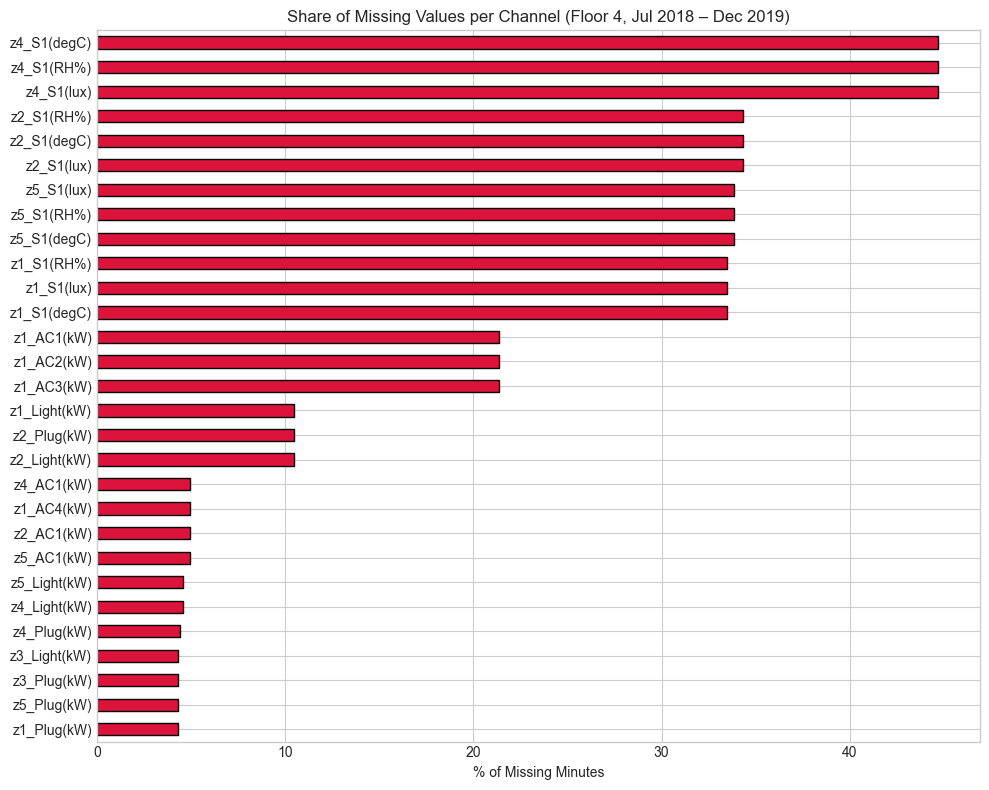

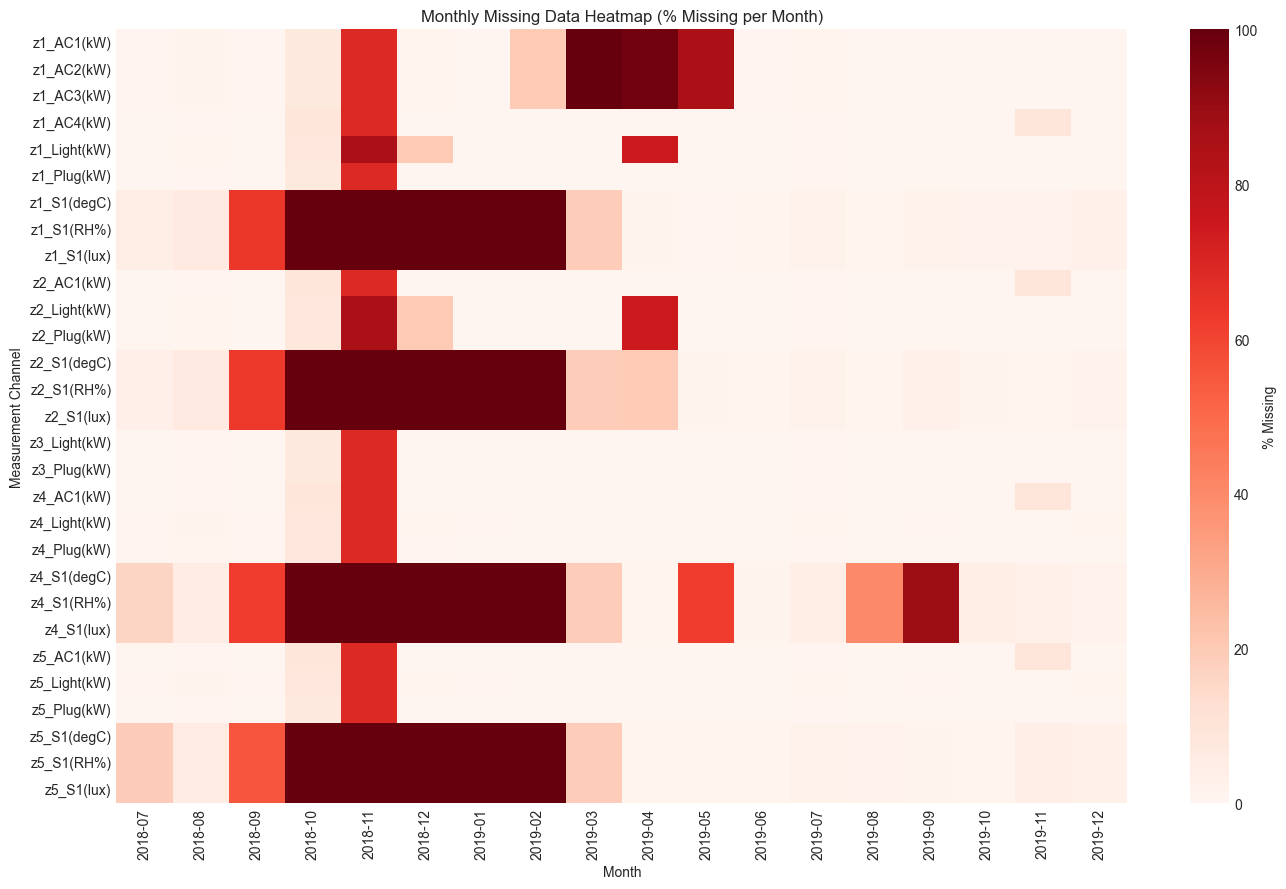

First day with ZERO temp readings: 2018-09-15
Last day with ZERO temp readings : 2019-03-05
Total consecutive blackout days : 172


In [5]:
# 1. Overall missingness bar plot
missing_pct = df.isna().mean().mul(100).round(2).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
missing_pct.plot.barh(color="crimson", edgecolor="black")
plt.xlabel("% of Missing Minutes")
plt.title("Share of Missing Values per Channel (Floor 4, Jul 2018 – Dec 2019)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 2. Monthly missing heatmap
monthly_missing = df.isna().resample("MS").mean().mul(100)
monthly_missing.index = monthly_missing.index.strftime("%Y-%m")

plt.figure(figsize=(14, 9))
sns.heatmap(monthly_missing.T, cmap="Reds", vmin=0, vmax=100, cbar_kws={'label': '% Missing'})
plt.title("Monthly Missing Data Heatmap (% Missing per Month)")
plt.xlabel("Month")
plt.ylabel("Measurement Channel")
plt.tight_layout()
plt.show()

# 3. System-wide temperature blackout quantification
temp_present = df[TEMP_COLS].notna().any(axis=1)
daily_present = temp_present.resample("D").mean()
gap_days = daily_present[daily_present == 0]

print("First day with ZERO temp readings:", gap_days.index.min().date())
print("Last day with ZERO temp readings :", gap_days.index.max().date())
print("Total consecutive blackout days :", len(gap_days))

## 7. Looking for Impossible Values and Meter Glitches

Examining summary distributions, minima, and maxima across all channels to detect anomalous readings, electrical transients, and hardware clipping.

In [6]:
# Statistical Summary
summary = df.describe().T[['count', 'mean', 'min', '50%', 'max']].round(2)
display(summary.sort_values(by='max', ascending=False))

# Compare year-over-year peak loads to isolate meter glitches
max_2018 = df.loc['2018', POWER_COLS].max()
max_2019 = df.loc['2019', POWER_COLS].max()
ratio = (max_2018 / max_2019).round(1)
spike_df = pd.DataFrame({'Max 2018 (kW)': max_2018, 'Max 2019 (kW)': max_2019, 'Ratio 2018/2019': ratio})
display(spike_df.sort_values(by='Ratio 2018/2019', ascending=False).head(10))

,count,mean,min,50%,max
z4_S1(lux),437367.0,25.26,0.00,5.00,111.00
z1_Plug(kW),756532.0,1.01,0.00,0.39,87.11
z1_S1(lux),526127.0,23.25,0.00,2.00,87.00
z5_S1(lux),522796.0,18.56,0.00,0.00,87.00
z4_S1(RH%),437367.0,63.41,47.92,63.36,85.30
z2_S1(lux),519027.0,17.32,0.00,0.00,85.00
z5_S1(RH%),522796.0,67.63,44.91,67.74,84.81
z2_S1(RH%),519026.0,66.42,50.70,66.44,81.11
z1_S1(RH%),526128.0,62.44,45.12,62.48,78.80
z1_Light(kW),707605.0,1.58,0.00,0.01,63.11


,Max 2018 (kW),Max 2019 (kW),Ratio 2018/2019
z1_AC1(kW),22.29,1.26,17.7
z1_Plug(kW),87.11,6.15,14.2
z5_Light(kW),58.61,6.38,9.2
z2_Light(kW),32.59,6.27,5.2
z1_AC3(kW),9.91,2.06,4.8
z1_Light(kW),63.11,14.62,4.3
z1_AC2(kW),20.28,4.92,4.1
z3_Light(kW),8.55,3.08,2.8
z4_Light(kW),26.70,12.69,2.1
z4_Plug(kW),9.52,5.28,1.8


**Findings on Extreme Values & Meter Glitches:**
- **Single-Minute Power Spikes in 2018:**
  - `z1_Plug(kW)` recorded an extreme peak of **87.11 kW** in 2018 versus a maximum of **6.15 kW** in 2019 (a 14.2× ratio).
  - `z1_Light(kW)` reached **63.11 kW** in 2018 versus **14.62 kW** in 2019 (a 4.3× ratio).
  - `z5_Light(kW)` spiked to **58.61 kW** in 2018 versus **6.38 kW** in 2019 (a 9.2× ratio).
  - Individual branch circuits for lighting and wall sockets cannot draw 50–90 kW under normal operation. These isolated spikes are meter artifacts that must be clipped to `NaN` prior to cumulative energy calculations.
- **AC Allocation Asymmetry:**
  - In Zone 1, `z1_AC4(kW)` delivers the vast majority of active cooling (averaging ~4.75 kW with peaks up to 51.69 kW).
  - Conversely, `z1_AC1`, `z1_AC2`, and `z1_AC3` draw near 0.00 kW mean power, operating almost exclusively in an idle or backup state.
- **Physical Plausibility of Environmental Sensors:**
  - Floor 4 indoor temperatures stay within a realistic range of **16.19°C to 31.90°C**, without the sub-11°C anomalous readings observed on other floors.

### Visualizing Outliers via Time-Series Scatter Plots (Plug, Light, and AC)

To visually verify whether the 2018 peak readings are isolated single-minute telemetry transients or sustained high loads, we plot the power readings over time against their domain-driven operational thresholds:

- **Lighting & Plug Circuits (`z1_Plug`, `z1_Light`, `z5_Light`):** Normal baseline operations form a dense cloud under 6 kW, whereas transient telemetry glitches spike as high as 58 kW to 87 kW.
- **Auxiliary AC Units (`z1_AC1`, `z1_AC2`, `z1_AC3`):** Under standard conditions, these units operate mostly idle or under 3 kW. However, during the logger reboot event on 2018-11-21, they simultaneously registered non-physical surges between 10 kW and 22 kW.

As shown below, the dashed threshold lines isolate these detached, single-minute red outliers without clipping any valid 2019 operational peaks.

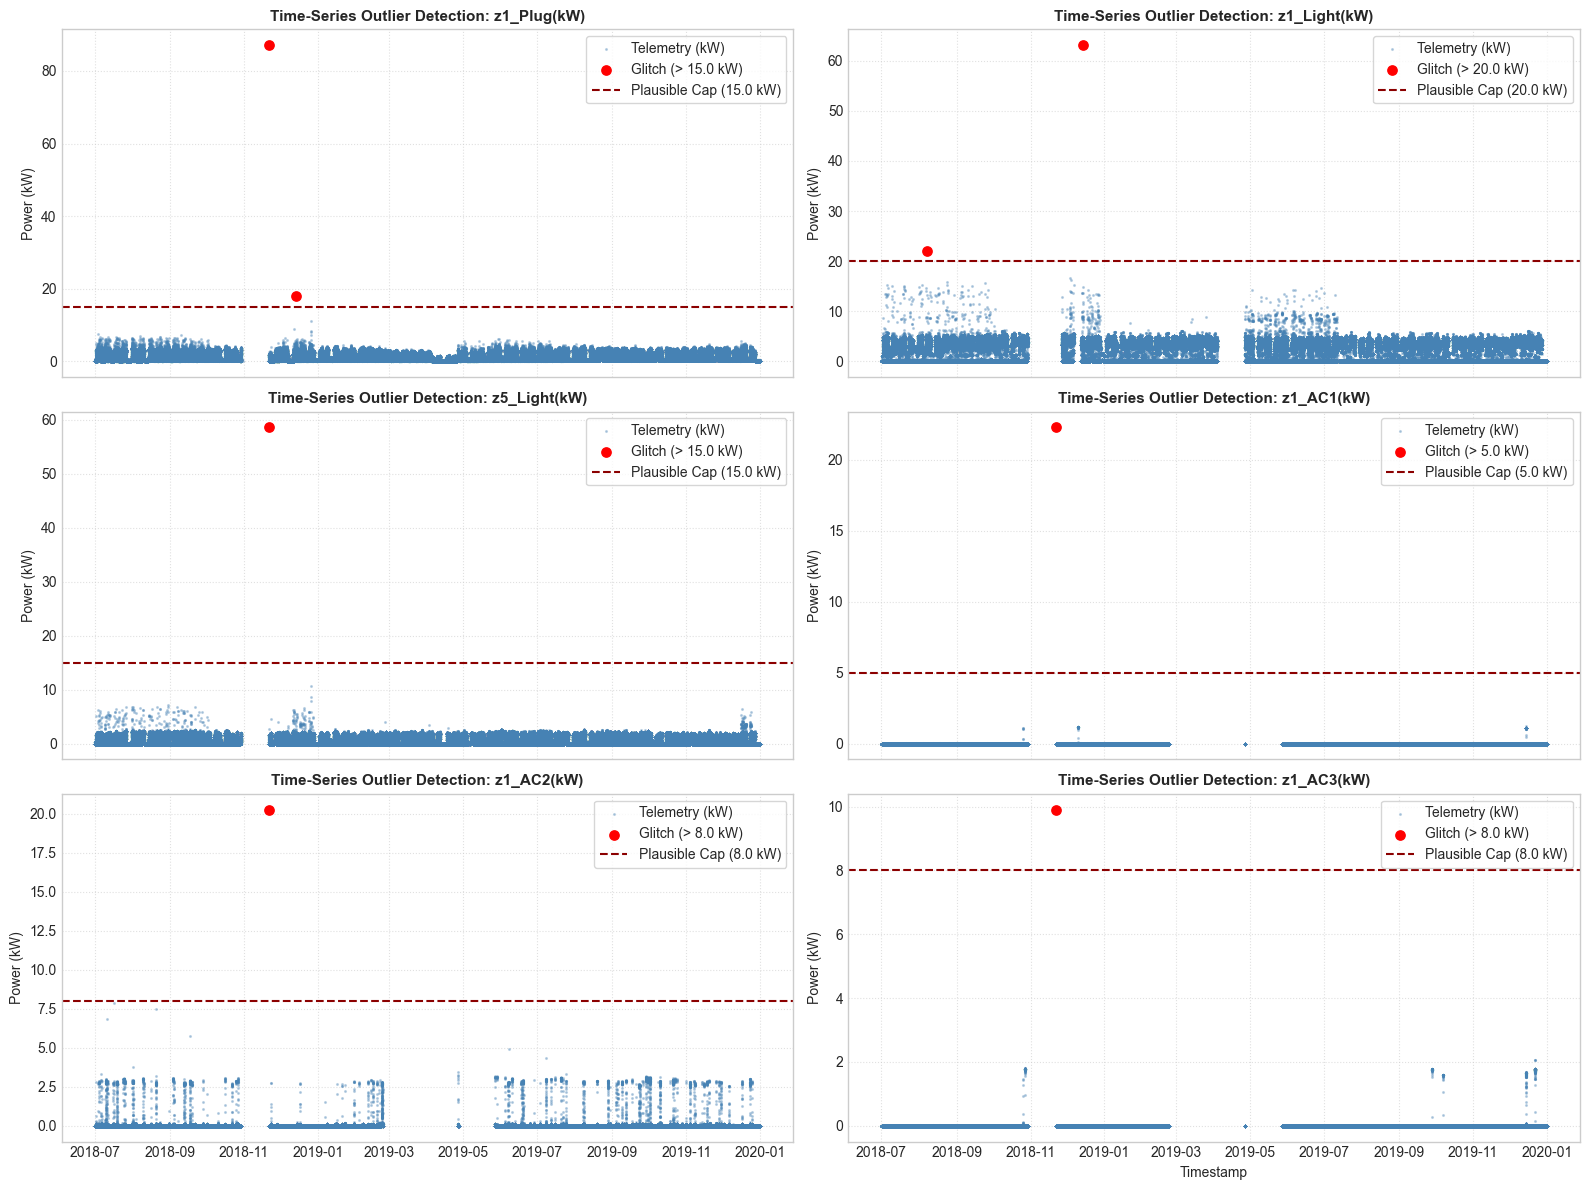

In [7]:
# Scatter plots to visually inspect isolated spikes across Plug, Light, and AC circuits
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True)

# Key channels across Plug, Light, and AC displaying telemetry anomalies
glitch_channels = [
    'z1_Plug(kW)', 'z1_Light(kW)', 
    'z5_Light(kW)', 'z1_AC1(kW)', 
    'z1_AC2(kW)', 'z1_AC3(kW)'
]
thresholds = [15.0, 20.0, 15.0, 5.0, 8.0, 8.0]

for idx, (col, cap) in enumerate(zip(glitch_channels, thresholds)):
    ax = axes[idx // 2, idx % 2]
    
    # 1. Plot normal operational data as a semi-transparent scatter cloud
    ax.scatter(df.index, df[col], alpha=0.3, s=1.5, color='steelblue', label='Telemetry (kW)')
    
    # 2. Highlight transient outliers exceeding the threshold in red
    spikes = df[df[col] > cap]
    ax.scatter(spikes.index, spikes[col], color='red', s=45, zorder=5, label=f'Glitch (> {cap} kW)')
    
    # 3. Draw the domain-driven threshold cap
    ax.axhline(cap, color='darkred', linestyle='--', linewidth=1.5, label=f'Plausible Cap ({cap} kW)')
    
    ax.set_title(f"Time-Series Outlier Detection: {col}", fontsize=11, fontweight='bold')
    ax.set_ylabel("Power (kW)")
    ax.legend(loc='upper right', frameon=True)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.xlabel("Timestamp")
plt.tight_layout()
plt.show()

## 8. Data Cleaning: Outlier Capping

Isolated non-physical spikes exceeding plausible circuit thresholds are replaced with `NaN` so they do not artificially inflate cumulative energy calculations.

In [8]:
# Realistic power caps derived from zone capacity and 2019 operational thresholds
GLITCH_CAPS_F4 = {
    'z1_Plug(kW)': 15.0,
    'z1_Light(kW)': 20.0,
    'z5_Light(kW)': 15.0,
    'z2_Light(kW)': 15.0,
    'z1_AC1(kW)': 5.0,
    'z1_AC2(kW)': 8.0,
    'z1_AC3(kW)': 8.0,
    'z4_Light(kW)': 20.0
}

df_clean = df.copy()
for col, cap in GLITCH_CAPS_F4.items():
    if col in df_clean.columns:
        spike_mask = df_clean[col] > cap
        print(f"{col}: {spike_mask.sum()} samples exceeding {cap} kW replaced with NaN")
        df_clean.loc[spike_mask, col] = np.nan

z1_Plug(kW): 2 samples exceeding 15.0 kW replaced with NaN
z1_Light(kW): 2 samples exceeding 20.0 kW replaced with NaN
z5_Light(kW): 1 samples exceeding 15.0 kW replaced with NaN
z2_Light(kW): 1 samples exceeding 15.0 kW replaced with NaN
z1_AC1(kW): 1 samples exceeding 5.0 kW replaced with NaN
z1_AC2(kW): 1 samples exceeding 8.0 kW replaced with NaN
z1_AC3(kW): 1 samples exceeding 8.0 kW replaced with NaN
z4_Light(kW): 1 samples exceeding 20.0 kW replaced with NaN


On 2018-11-21 at 15:20:00, the data stream recovered from a short communication dropout (NaN at 15:18 and 15:19). Upon reconnecting at 15:20, multiple meters concurrently recorded surge values:

- z1_Plug(kW): 87.11 kW (dropped back to 1.89 kW at 15:21)
- z5_Light(kW): 58.61 kW (dropped back to 1.54 kW at 15:21)
- z1_AC1(kW): 22.29 kW (dropped back to 0.00 kW at 15:21)
- z1_AC2(kW): 20.28 kW
- z1_AC3(kW): 9.91 kW

Across the entire 790,560-minute dataset, these caps flag only 1 to 2 isolated minutes per channel (all situated in late 2018), resulting in 0 false positives in 2019.
This confirms the caps target bad sensor telemetry while preserving legitimate operational load dynamics.

## 9. Floor 4 Energy Consumption Breakdown

Power readings ($P$, in kW) logged at 1-minute intervals are integrated into cumulative daily energy ($E$, in kWh) using:
$$E_{\text{kWh}} = \sum P_{\text{kW}} \times \frac{1}{60}\,\text{h}$$

We quantify consumption across two complementary dimensions:
1. **End-Use Category:** Air Conditioning (`AC`), Lighting (`Light`), and Socket loads (`Plug`).
2. **Spatial Distribution:** Total energy consumed per zone (`z1` through `z5`).

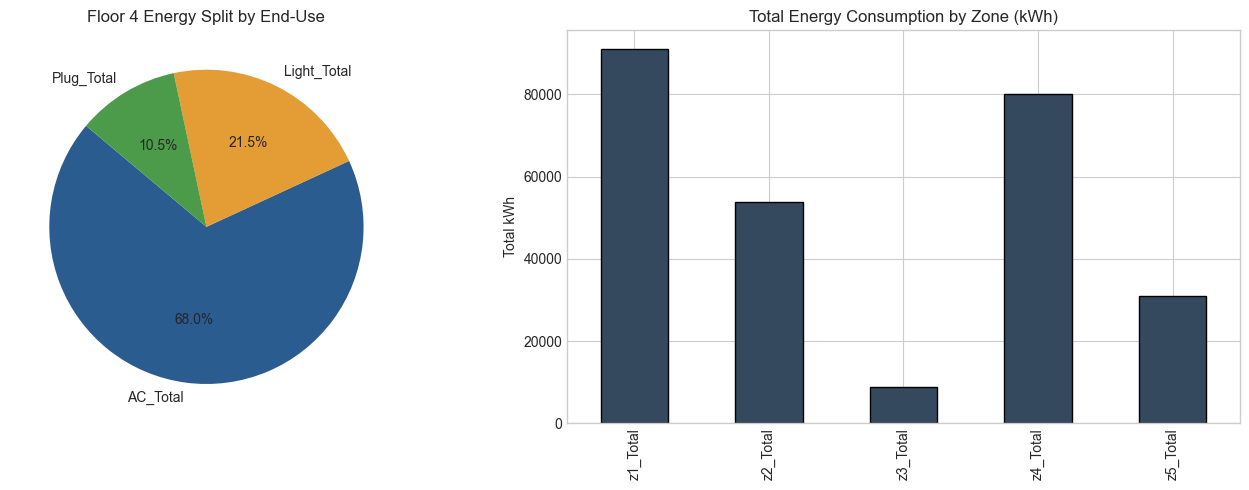

In [9]:
# Convert clean kW power to kWh/day
daily_energy = df_clean[POWER_COLS].resample("D").sum().mul(1/60)

# End-use aggregation
daily_energy["AC_Total"] = daily_energy[AC_COLS].sum(axis=1)
daily_energy["Light_Total"] = daily_energy[LIGHT_COLS].sum(axis=1)
daily_energy["Plug_Total"] = daily_energy[PLUG_COLS].sum(axis=1)
daily_energy["Floor4_Total"] = daily_energy[["AC_Total", "Light_Total", "Plug_Total"]].sum(axis=1)

# Zone aggregation
for z in ['z1', 'z2', 'z3', 'z4', 'z5']:
    z_cols = [c for c in POWER_COLS if c.startswith(z)]
    daily_energy[f"{z}_Total"] = daily_energy[z_cols].sum(axis=1)

# Visualizing End-Use Distribution
end_use_totals = daily_energy[["AC_Total", "Light_Total", "Plug_Total"]].sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

end_use_totals.plot.pie(ax=ax[0], autopct='%1.1f%%', colors=['#2b5c8f', '#e39d34', '#4b9b4b'], startangle=140)
ax[0].set_title("Floor 4 Energy Split by End-Use")
ax[0].set_ylabel("")

daily_energy[["z1_Total", "z2_Total", "z3_Total", "z4_Total", "z5_Total"]].sum().plot.bar(ax=ax[1], color='#34495e', edgecolor='black')
ax[1].set_title("Total Energy Consumption by Zone (kWh)")
ax[1].set_ylabel("Total kWh")
plt.tight_layout()
plt.show()

## 10. Operational Profiles: Diurnal Curves (Daily; 24-Hour Cycle) and Baseloads

Evaluating typical 24-hour load shapes for representative high-demand circuits, contrasting working weekdays against weekends to detect after-hours baseload leakage.

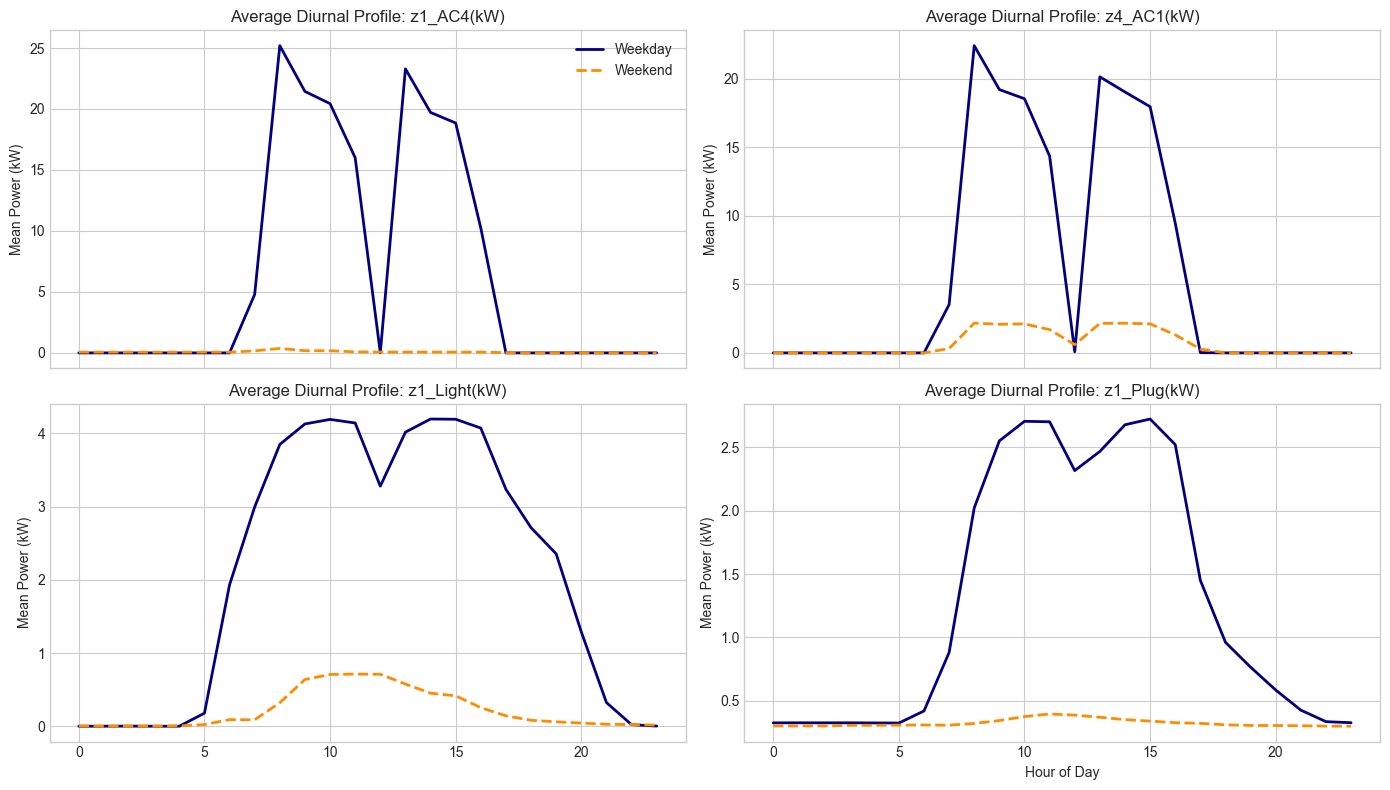

In [10]:
df_clean['Hour'] = df_clean.index.hour
df_clean['DayOfWeek'] = df_clean.index.dayofweek
df_clean['IsWeekend'] = df_clean['DayOfWeek'].isin([5, 6])

hourly_profile = df_clean.groupby(['IsWeekend', 'Hour'])[['z1_AC4(kW)', 'z4_AC1(kW)', 'z1_Light(kW)', 'z1_Plug(kW)']].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
channels = ['z1_AC4(kW)', 'z4_AC1(kW)', 'z1_Light(kW)', 'z1_Plug(kW)']

for idx, ch in enumerate(channels):
    ax = axes[idx//2, idx%2]
    ax.plot(hourly_profile.loc[False].index, hourly_profile.loc[False, ch], label='Weekday', color='navy', lw=2)
    ax.plot(hourly_profile.loc[True].index, hourly_profile.loc[True, ch], label='Weekend', color='darkorange', lw=2, linestyle='--')
    ax.set_title(f"Average Diurnal Profile: {ch}")
    ax.set_ylabel("Mean Power (kW)")
    ax.grid(True)
    if idx == 0:
        ax.legend()

plt.xlabel("Hour of Day")
plt.tight_layout()
plt.show()

## 11. Indoor Environmental Quality (IEQ) Compliance

Restricting analysis to periods of verified sensor operation (post-5 March 2019), we evaluate temperature, relative humidity, and illuminance distributions against standard tropical office comfort thresholds (e.g., ASHRAE 55: 23°C–26°C, 50%–70% RH).

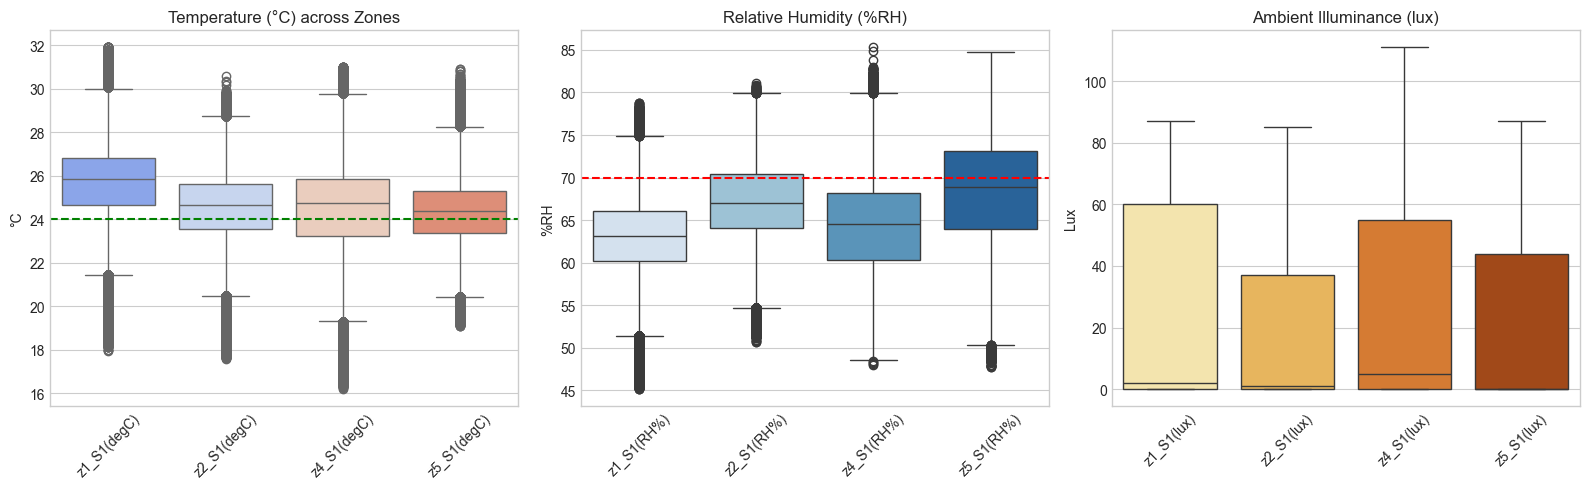

In [11]:
# Filter out the blackout window (use valid periods: Jul-Sep 2018 & Mar-Dec 2019)
valid_ieq = df_clean.loc[df_clean.index >= '2019-03-06', IEQ_COLS]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Temperature Boxplot
sns.boxplot(data=valid_ieq[TEMP_COLS], ax=axes[0], palette="coolwarm")
axes[0].set_title("Temperature (°C) across Zones")
axes[0].axhline(24, color='green', ls='--', label='24°C Comfort Target')
axes[0].set_ylabel("°C")

# Relative Humidity
sns.boxplot(data=valid_ieq[RH_COLS], ax=axes[1], palette="Blues")
axes[1].set_title("Relative Humidity (%RH)")
axes[1].axhline(70, color='red', ls='--', label='70% Upper Bound')
axes[1].set_ylabel("%RH")

# Illuminance
sns.boxplot(data=valid_ieq[LUX_COLS], ax=axes[2], palette="YlOrBr")
axes[2].set_title("Ambient Illuminance (lux)")
axes[2].set_ylabel("Lux")

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 10. Conclusions & Engineering Recommendations

### Key Findings for Floor 4
1. **Infrastructure Downtime:**
   * An identical **172-day environmental sensor outage** occurred from **September 15, 2018 to March 5, 2019** where all temperature, humidity, and lux sensors flatlined. Any thermal comfort or building envelope modeling must exclude this interval.
2. **Sub-meter Sensor Glitches in 2018:**
   * High-magnitude single-minute transients were detected in 2018: `z1_Plug` (up to 87.1 kW), `z1_Light` (63.1 kW), and `z5_Light` (58.6 kW). These were 4× to 17× higher than realistic 2019 operations and were successfully clipped to prevent cumulative energy distortion.
3. **HVAC Load Asymmetry:**
   * In Zone 1, `z1_AC4` delivers almost all dynamic cooling. Units `AC1`, `AC2`, and `AC3` draw negligible load (~0.01 kW average), functioning as idle or redundant circuits. Zones 2 and 4 represent major thermal loads with typical operational draws of 30–50 kW during operating hours.
4. **IEQ Compliance:**
   * Post-March 2019 temperatures remain stable, averaging 24.5°C to 25.7°C across zones, aligning with tropical office comfort standards. However, relative humidity frequently exceeds 70%, increasing latent cooling loads and mold risk.

### Actionable Recommendations
* **Firmware & BMS Gateway Heartbeat Monitoring:** Install an automated watchdog service on the IoT gateway to trigger immediate IT alerts if multiple environmental channels simultaneously drop out for >30 minutes.
* **HVAC Staging & Commissioning in Zone 1:** Audit `z1_AC1`, `z1_AC2`, and `z1_AC3`. If these units are physical split units, verify whether the BMS is failing to stage them during peak thermal hours, or consolidate metering points if `AC4` is the primary package unit.
* **Night-Time Baseload Mitigation:** Schedule automated lighting sweeps and smart plug timers in Zones 1 and 4 to eliminate ghost plug loads and after-hours lighting left on over weekends.